# 08 — Causal inference: did the target lower the spending?

A forecast answers "what will happen"; a household also asks "**what did my decision do**?" —
say, a budget target set on groceries from March (F-BUD-1 records that month). That is a causal
question: the effect is the gap between what was spent and what **would have been spent
without the target**, a counterfactual nobody observes.

The synthetic panel lets us answer it with the truth known: 51 households received, from a
known month, a cut of 10 to 25 % in one category's level (groceries, leisure or shopping). We
estimate those effects with three designs and check each against the truth:

1. **Counterfactual forecasting** (the idea of Google's CausalImpact): train a forecaster on the
   months **before** the target, forecast the months after, and read the effect as
   1 − actual / forecast. Its uncertainty comes from **placebos in space**: the same estimate on
   the same category of households **without** a target, at the same month, gives the
   distribution of "effects" that noise and forecast error alone produce.
2. **Difference-in-differences** (DiD): the change from before to after in the treated series,
   against the same change in controls over the same calendar months (which removes seasonality
   and common shocks): (a) the same category in households without a target; (b) **the
   household's own other categories**, the only controls the app would have.
3. **Placebo in time**: the counterfactual estimate at a fake date a year **before** the real
   one, where the true effect is zero: how often does it "find" something?

The assumptions are stated at the end, with why the app does not show this yet.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsforecast import StatsForecast
from statsforecast.models import AutoETS, WindowAverage

import study

warnings.filterwarnings("ignore")
df, interventions = study.full_panel()
iv = pd.DataFrame([vars(i) for i in interventions])
treated_h = set(iv["household"])
last = df["ds"].max()
iv["start"] = [df.loc[(df.household == r.household), "ds"].min() + pd.DateOffset(months=int(r.month)) for r in iv.itertuples()]
iv["post months"] = [(last.year - s.year) * 12 + last.month - s.month + 1 for s in iv["start"]]
print(f"{len(iv)} interventions; effects from {iv.effect.min():.0%} to {iv.effect.max():.0%}; "
      f"{iv['post months'].min()} to {iv['post months'].max()} months after")
iv.groupby("category")["effect"].describe()[["count", "mean", "min", "max"]].round(3)

51 interventions; effects from 10% to 25%; 7 to 14 months after


,count,mean,min,max
category,,,,
Groceries,22.0,0.185,0.114,0.249
Leisure,11.0,0.177,0.109,0.249
Shopping,18.0,0.162,0.097,0.220


In [2]:
series = df.pivot_table(index="ds", columns=["household", "category"], values="variable")

def counterfactual(h: int, cat: str, start: pd.Timestamp, end: pd.Timestamp, model) -> float:
    """1 - actual / forecast over [start, end], the forecaster trained before `start`."""
    y = series[(h, cat)].dropna()
    pre = y[y.index < start]
    post = y[(y.index >= start) & (y.index <= end)]
    if len(pre) < 13 or post.sum() <= 0:
        return np.nan
    f = StatsForecast(models=[model], freq="MS").forecast(
        df=pd.DataFrame({"unique_id": "x", "ds": pre.index, "y": pre.to_numpy()}), h=len(post))
    return float(1 - post.sum() / f.iloc[:, -1].sum())

MODELS = {"ETS": lambda: AutoETS(season_length=12), "Mean12": lambda: WindowAverage(12)}

def estimate_all() -> pd.DataFrame:
    rng = np.random.default_rng(0)
    rows = []
    for r in iv.itertuples():
        controls = [h for h in df["household"].unique() if h not in treated_h
                    and series[(h, r.category)].dropna().index.min() <= r.start - pd.DateOffset(months=24)]
        controls = list(rng.choice(controls, size=min(30, len(controls)), replace=False))
        for name, make in MODELS.items():
            est = counterfactual(r.household, r.category, r.start, last, make())
            placebo = [counterfactual(c, r.category, r.start, last, make()) for c in controls]
            fake = r.start - pd.DateOffset(months=12)
            in_time = counterfactual(r.household, r.category, fake, fake + pd.DateOffset(months=int(r._6) - 1), make())
            rows.append({"household": r.household, "category": r.category, "effect": r.effect,
                         "post": r._6, "model": name, "estimate": est, "in_time": in_time,
                         "placebos": np.array(placebo, dtype=float)})
    out = pd.DataFrame(rows)
    out["placebos"] = out["placebos"].apply(list)
    return out

est = study.cached("causal_counterfactual", estimate_all)
est["placebos"] = est["placebos"].apply(np.asarray)
est.head(3)[["household", "category", "effect", "model", "estimate", "in_time"]]

,household,category,effect,model,estimate,in_time
0,0,Groceries,0.248670,ETS,0.235103,-0.091107
1,0,Groceries,0.248670,Mean12,0.261360,-0.088067
2,4,Groceries,0.193637,ETS,0.167175,-0.044593


## 1. Counterfactual forecasting

The placebo distribution gives an 80 % interval (estimate minus the placebos' 90th and 10th
percentiles) and a p-value (the share of placebos at least as large as the estimate).

In [3]:
def summarise(e: pd.DataFrame) -> pd.Series:
    lo = e.apply(lambda r: r.estimate - np.nanquantile(r.placebos, 0.9), axis=1)
    hi = e.apply(lambda r: r.estimate - np.nanquantile(r.placebos, 0.1), axis=1)
    p = e.apply(lambda r: (np.sum(r.placebos >= r.estimate) + 1) / (np.sum(~np.isnan(r.placebos)) + 1), axis=1)
    err = e["estimate"] - e["effect"]
    return pd.Series({
        "mean abs error (points)": float(np.nanmean(np.abs(err)) * 100),
        "bias (points)": float(np.nanmean(err) * 100),
        "correlation with truth": float(e[["estimate", "effect"]].corr().iloc[0, 1]),
        "80 % interval covers truth": float(np.mean((lo <= e["effect"]) & (e["effect"] <= hi))),
        "detected at 5 %": float(np.mean(p < 0.05)),
        "placebo in time 'detected' (should be ~0)": float(np.mean(e["in_time"] > e.apply(lambda r: np.nanquantile(r.placebos, 0.95), axis=1))),
        "placebo in time, mean (points)": float(np.nanmean(e["in_time"]) * 100),
    })

pd.DataFrame({m: summarise(g) for m, g in est.groupby("model")}).round(3)

,ETS,Mean12
mean abs error (points),9.360,8.364
bias (points),-1.659,-1.684
correlation with truth,0.263,0.269
80 % interval covers truth,0.882,0.882
detected at 5 %,0.451,0.451
placebo in time 'detected' (should be ~0),0.078,0.098
"placebo in time, mean (points)",-8.269,-4.801


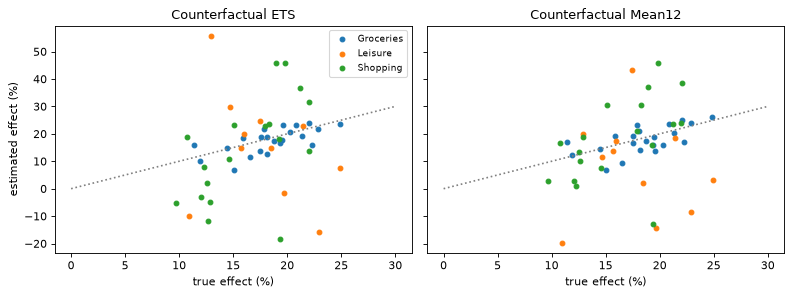

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, (m, g) in zip(axes, est.groupby("model")):
    for cat, gg in g.groupby("category"):
        ax.scatter(gg.effect * 100, gg.estimate * 100, s=18, label=cat)
    ax.plot([0, 30], [0, 30], ls=":", color="grey")
    ax.set(title=f"Counterfactual {m}", xlabel="true effect (%)")
axes[0].set_ylabel("estimated effect (%)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. Difference-in-differences

Over the 12 months before the target and the months after it, with (a) the same category in up
to 30 households without a target, or (b) the treated household's own other variable categories
(groceries, leisure, shopping, transport, miscellaneous, children, but the treated one):

In [5]:
OTHER = ["Groceries", "Leisure", "Shopping", "Transport", "Miscellaneous", "Children"]

def did(r, controls: list[tuple[int, str]]) -> float:
    pre = (series.index >= r.start - pd.DateOffset(months=12)) & (series.index < r.start)
    post = series.index >= r.start
    t = series[(r.household, r.category)]
    c = series[controls].sum(axis=1)
    return float(1 - (t[post].sum() / t[pre].sum()) / (c[post].sum() / c[pre].sum()))

rows = []
rng = np.random.default_rng(1)
for r in iv.itertuples():
    others = [h for h in df["household"].unique() if h not in treated_h
              and series[(h, r.category)].dropna().index.min() <= r.start - pd.DateOffset(months=12)]
    others = list(rng.choice(others, size=min(30, len(others)), replace=False))
    own = [(r.household, c) for c in OTHER if c != r.category]
    rows.append({"effect": r.effect, "category": r.category,
                 "DiD, other households": did(r, [(h, r.category) for h in others]),
                 "DiD, own other categories": did(r, own)})
dd = pd.DataFrame(rows)
pd.DataFrame({
    m: {"mean abs error (points)": np.mean(np.abs(dd[m] - dd.effect)) * 100,
        "bias (points)": np.mean(dd[m] - dd.effect) * 100,
        "correlation with truth": dd[[m, "effect"]].corr().iloc[0, 1]}
    for m in ["DiD, other households", "DiD, own other categories"]
}).round(3)

,"DiD, other households","DiD, own other categories"
mean abs error (points),8.430,9.782
bias (points),-1.155,0.352
correlation with truth,0.228,0.200


## Power: which effects can be seen

Detection at 5 % (counterfactual ETS with placebo p-value) by size of the true effect and by
category:

In [6]:
e = est[est.model == "ETS"].copy()
e["p"] = e.apply(lambda r: (np.sum(r.placebos >= r.estimate) + 1) / (np.sum(~np.isnan(r.placebos)) + 1), axis=1)
e["size"] = pd.cut(e.effect, [0.08, 0.13, 0.19, 0.25], labels=["8–13 %", "13–19 %", "19–25 %"], include_lowest=True)
print(e.groupby("size", observed=True)["p"].apply(lambda p: (p < 0.05).mean()).round(2).to_string())
print(e.groupby("category")["p"].apply(lambda p: (p < 0.05).mean()).round(2).to_string())

size
8–13 %     0.09
13–19 %    0.45
19–25 %    0.65
category
Groceries    0.77
Leisure      0.18
Shopping     0.22


## What the causal designs show

**On average, the effects are recovered; one household at a time, poorly.**

- The counterfactual forecast (ETS or the 12-month mean) is nearly unbiased across the 51
  targets (−1.7 points), but a single estimate misses the truth by **8 to 9 points** on
  average, for true effects of 10 to 25 %: the correlation between estimate and truth is only
  about 0.27. A month's noise in a household's category is as large as the effect sought.
- **The placebo-in-space intervals are honest**: the 80 % interval covers the true effect in
  88 % of the cases (conservative), so the uncertainty can be stated. But the effect is
  **detected** (p < 5 %) in only 45 % of the cases: 77 % for groceries (low noise), 18–22 % for
  leisure and shopping, and 9 % when the true effect is below 13 %.
- **The placebo in time is the test that catches the trap**: a year before the target, where
  the truth is zero, the counterfactual "finds" an effect of **−8 points** with ETS (−5 with the
  12-month mean), flagged as significant 8–10 % of the time against 5 % nominal. With 13 to 23
  months of pre-period, the forecaster has not learnt the yearly season, so a December or a summer
  in the window reads as an effect. Any such feature must run this test and say so.
- **Difference-in-differences** does about as well (error 8.4 points against other households,
  9.8 against the household's own other categories) with a smaller bias, the own-category version
  almost none (+0.4 point): the calendar months cancel between treated and controls.

## The assumptions, and why the app does not show this yet

1. **No confounding of the timing.** A household sets a target **because** a category ran
   high: the months after would fall back anyway (**regression to the mean**), and the method
   would credit the target. The synthetic interventions here start at random months, so this
   bias is absent from the numbers above; in real use it would inflate every effect.
2. **No spill-over (SUTVA).** Spending cut on leisure may move to shopping. The household's own
   other categories, the only controls the app has, are then contaminated: the DiD on them would
   understate or overstate the effect.
3. **Parallel trends / a stable model.** DiD needs the controls to move as the treated series
   would have; the counterfactual needs the pre-period model to stay right, which the placebo in
   time showed it does not with less than two years.
4. **No other change at the same time** (a move, a new job, a child), which the app cannot know.

With one household, no other household to compare with (the app must not collect any), a
detection rate of about one in two for effects of 10–25 % and a confounder built into the
decision itself, a "your target saved €X" figure would too often be noise or the regression to
the mean presented as a result. A future version could offer it **only** for low-noise
categories, with at least 24 months before the target, the placebo-in-time check passed, the
interval shown, and wording that says what it cannot rule out.